<a href="https://colab.research.google.com/github/essensha/cs2-anti-cheat-ml-research/blob/main/Anti_Cheating_Skill_Parsing_and_Productionalization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

import pandas as pd

df = pd.read_csv("/srv/synthetic_anticheat_telemetry.csv")

print("Dataset shape:", df.shape)
display(df.head(10))


Dataset shape: (12001, 1)


,,,,,,,,,,synthetic_anticheat_telemetry
player_id,match_id,match_day,skill_proxy,actions_per_min,median_reaction_ms,timing_regularities,target_accuracy,repeated_action_ratio,synthetic_pattern,is_suspicious_simulated
100000,204010,27,0.616,151.3,334.8,0.383,0.51,0.066,normal,0
100001,200988,18,0.333,143.9,290.8,0.24,0.366,0.026,normal,0
100002,204639,52,0.741,155.3,172.5,0.537,0.613,0.421,normal,0
100003,203584,31,0.328,127.1,249.7,0.255,0.309,0.146,normal,0
100004,204014,19,0.418,129.4,247.0,0.176,0.46,0.204,normal,0
100005,201570,52,0.509,334.5,276.9,0.13,0.561,0.585,automation_pattern,1
100006,203237,15,0.376,118.3,359.8,0.556,0.441,0.064,normal,0
100007,202491,12,0.686,170.0,260.2,0.045,0.578,0.196,normal,0
100008,201135,32,0.708,153.7,237.6,0.299,0.539,0.165,normal,0


In [ ]:
#Here where seeing shape and rows, columns, type of data, Missing value (which is 0), with nearly 12000 of duplicated rows, and random state to select certain probabilitywe see the shape and rows, columns, type of data, Missing value (which is 0), with nearly 12000 of duplicated rows, and random state to select certain probabilityHere, seeing shape and rows, columns, type of data, Missing value (which is 0), with nearly 12000 of duplicated rows, and random state to select certain probabilitywe see the shape and rows, columns, type of data, Missing value (which is 0), with nearly 12000 of duplicated rows, and random state to select certain probability#abilitywe see the shape and rows, columns, type of data, Missing value (which is 0), with nearly 12000 of duplicated rows, and random state to select certain probabilityHere, seeing shape and rows, columns, type of data, Missing value (which is 0), with nearly 12000 of duplicated rows, and random state to select certain probabilitywe see the shape and rows, columns, type of data, Missing value (which is 0), with nearly 12000 of duplicated rows, and random state to select certain probability
#a reaction-time column could contain negative values, a player could appear in multiple matches, and a suspicious-behavior label might accidentally leak into the training features. Each creates a different modeling risk
import pandas as pd

# Basic dataset structure
print("Shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
display(df.isna().sum().to_frame("missing_count"))

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nSample observations:")
display(df.sample(min(10, len(df)), random_state=42))


Shape: (12001, 1)

Column names:
['synthetic_anticheat_telemetry']

Data types:
synthetic_anticheat_telemetry    object
dtype: object

Missing values:


,missing_count
synthetic_anticheat_telemetry,0



Duplicate rows:
11998

Sample observations:


,,,,,,,,,,synthetic_anticheat_telemetry
102270,204458,30,0.564,145.0,266.2,0.071,0.574,0.176,normal,0
103494,200401,28,0.288,135.3,284.7,0.118,0.298,0.175,normal,0
110264,204877,19,0.559,151.0,226.5,0.088,0.413,0.205,normal,0
105738,201219,39,0.855,181.5,250.7,0.349,0.634,0.179,normal,0
100359,201705,26,0.641,158.2,294.6,0.265,0.563,0.082,normal,0
101500,203135,40,0.301,149.4,190.7,0.289,0.211,0.246,normal,0
110867,200437,11,0.272,128.0,446.6,0.355,0.361,0.206,normal,0
109796,203014,14,0.614,160.1,240.5,0.167,0.462,0.104,normal,0
108609,204982,57,0.222,103.9,278.8,0.268,0.351,0.108,normal,0
104617,202693,40,0.854,145.6,218.8,0.319,0.568,0.203,normal,0


pandas didn't parse your CSV into separate columns.

In [ ]:

file_path = "/srv/synthetic_anticheat_telemetry.csv"

with open(file_path, "r", encoding="utf-8-sig") as f:
    for _ in range(3):
        print(repr(f.readline()))


'synthetic_anticheat_telemetry\n'
'player_id,match_id,match_day,skill_proxy,actions_per_min,median_reaction_ms,timing_regularities,target_accuracy,repeated_action_ratio,synthetic_pattern,is_suspicious_simulated\n'
'100000,204010,27,0.616,151.3,334.8,0.383,0.51,0.066,normal,0\n'


In [ ]:

print("Column names:", df.columns.tolist())
print("Index levels:", df.index.nlevels) #Here index levels tells you how
print("First index value:", df.index[0])


Column names: ['synthetic_anticheat_telemetry']
Index levels: 10
First index value: ('player_id', 'match_id', 'match_day', 'skill_proxy', 'actions_per_min', 'median_reaction_ms', 'timing_regularities', 'target_accuracy', 'repeated_action_ratio', 'synthetic_pattern')


In [ ]:

import pandas as pd

df = pd.read_csv("/srv/synthetic_anticheat_telemetry.csv")

print("Dataset shape:", df.shape)
display(df.head(10))

#Uploading the proper data sets. Seeing the first 10 rows.


Dataset shape: (12001, 1)


,,,,,,,,,,synthetic_anticheat_telemetry
player_id,match_id,match_day,skill_proxy,actions_per_min,median_reaction_ms,timing_regularities,target_accuracy,repeated_action_ratio,synthetic_pattern,is_suspicious_simulated
100000,204010,27,0.616,151.3,334.8,0.383,0.51,0.066,normal,0
100001,200988,18,0.333,143.9,290.8,0.24,0.366,0.026,normal,0
100002,204639,52,0.741,155.3,172.5,0.537,0.613,0.421,normal,0
100003,203584,31,0.328,127.1,249.7,0.255,0.309,0.146,normal,0
100004,204014,19,0.418,129.4,247.0,0.176,0.46,0.204,normal,0
100005,201570,52,0.509,334.5,276.9,0.13,0.561,0.585,automation_pattern,1
100006,203237,15,0.376,118.3,359.8,0.556,0.441,0.064,normal,0
100007,202491,12,0.686,170.0,260.2,0.045,0.578,0.196,normal,0
100008,201135,32,0.708,153.7,237.6,0.299,0.539,0.165,normal,0


In [ ]:

import pandas as pd

file_path = "/srv/synthetic_anticheat_telemetry.csv"

# Reload and overwrite the old DataFrame
df = pd.read_csv(file_path, skiprows=1, index_col=False)

print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head(5))



Shape: (12000, 11)
Columns: ['player_id', 'match_id', 'match_day', 'skill_proxy', 'actions_per_min', 'median_reaction_ms', 'timing_regularities', 'target_accuracy', 'repeated_action_ratio', 'synthetic_pattern', 'is_suspicious_simulated']


,player_id,match_id,match_day,skill_proxy,actions_per_min,median_reaction_ms,timing_regularities,target_accuracy,repeated_action_ratio,synthetic_pattern,is_suspicious_simulated
0,100000,204010,27,0.616,151.3,334.8,0.383,0.510,0.066,normal,0
1,100001,200988,18,0.333,143.9,290.8,0.240,0.366,0.026,normal,0
2,100002,204639,52,0.741,155.3,172.5,0.537,0.613,0.421,normal,0
3,100003,203584,31,0.328,127.1,249.7,0.255,0.309,0.146,normal,0
4,100004,204014,19,0.418,129.4,247.0,0.176,0.460,0.204,normal,0


In [ ]:

print("Missing values:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Index levels:", df.index.nlevels)

assert df.shape == (12000, 11)
assert df.index.nlevels == 1

print("Data ingestion validation PASSED!")


Missing values: 0
Duplicate rows: 0
Index levels: 1
Data ingestion validation PASSED!


The data ingestion pipeline has passed validation.

Index identifies the rows of your DataFrame to point directly to data records whereas multi-index is hierarchical of various data points. While multi-index isn't bad you need a set organization (e.g., player + match)

In [ ]:

print("Index type:", type(df.index))
print("Index levels:", df.index.nlevels)
print("First five index values:", df.index[:5].tolist())

# Select the observation at index 0
display(df.loc[0])


Index type: <class 'pandas.core.indexes.range.RangeIndex'>
Index levels: 1
First five index values: [0, 1, 2, 3, 4]


,0
player_id,100000
match_id,204010
match_day,27
skill_proxy,0.616
actions_per_min,151.3
median_reaction_ms,334.8
timing_regularities,0.383
target_accuracy,0.51
repeated_action_ratio,0.066
synthetic_pattern,normal


Let's investigate whether individual players appear in multiple matches. This matters because repeated observations from the same player can introduce data leakage when we eventually split training and testing data.

In [ ]:

print("Total observations:", len(df))
print("Unique players:", df["player_id"].nunique())
print("Unique matches:", df["match_id"].nunique())

print("\nMatches per player:")
display(df.groupby("player_id").size().describe())


Total observations: 12000
Unique players: 12000
Unique matches: 4563

Matches per player:


,0
count,12000.0
mean,1.0
std,0.0
min,1.0
25%,1.0
50%,1.0
75%,1.0
max,1.0


Notice that we have 12,000 player observations but only 4,563 unique matches. That means multiple players can appear in the same match resulting in other forms of leakage

We need to investigate **match-level dependence** before choosing a validation strategy. I'd also check temporal leakage and whether all features would be available at inference time."

In [ ]:

# Count player observations per match
players_per_match = (
    df.groupby("match_id")
      .size()
      .rename("players_per_match")
)

print("Players per match:")
display(players_per_match.describe())

print("\nDistribution of match sizes:")
display(
    players_per_match.value_counts()
    .sort_index()
    .rename_axis("players_per_match")
    .to_frame("number_of_matches")
)

print("\nNumber of matches with multiple players:")
print((players_per_match > 1).sum())


Players per match:


,players_per_match
count,4563.000000
mean,2.629849
std,1.415129
min,1.000000
25%,2.000000
50%,2.000000
75%,3.000000
max,10.000000



Distribution of match sizes:


,number_of_matches
players_per_match,
1,1108
2,1298
3,1059
4,624
5,308
6,107
7,38
8,15
9,5



Number of matches with multiple players:
3455


Only about 0.02% of matches contain 10 observations, while 1,108 matches contain just one.

## Investigate temporal coverage

Minimum day: 0
Maximum day: 59
Unique days: 60


,match_day,observations
0,0,184
1,1,208
2,2,203
3,3,214
4,4,168
5,5,202
6,6,205
7,7,217
8,8,200
9,9,179


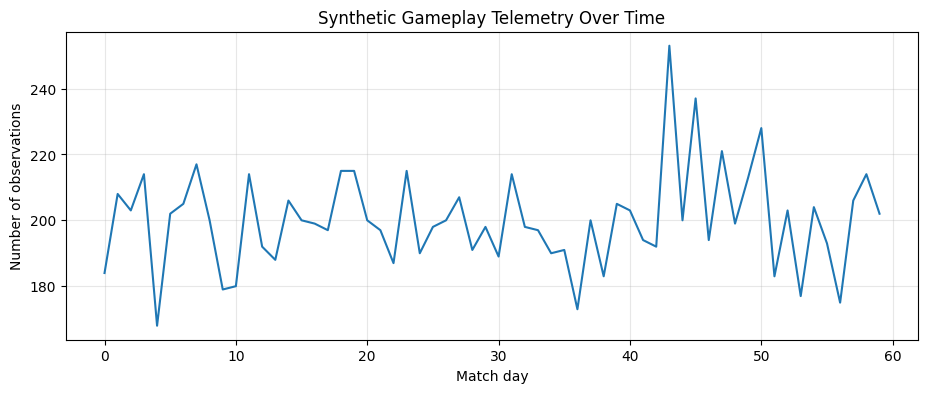

In [ ]:

# Examine the temporal structure
print("Minimum day:", df["match_day"].min())
print("Maximum day:", df["match_day"].max())
print("Unique days:", df["match_day"].nunique())

# Aggregate observations by day
daily_counts = (
    df.groupby("match_day")
      .size()
      .reset_index(name="observations")
      .sort_values("match_day")
)

display(daily_counts.head(10))

# Visualize activity over time
import matplotlib.pyplot as plt

plt.figure(figsize=(11, 4))
plt.plot(
    daily_counts["match_day"],
    daily_counts["observations"]
)

plt.xlabel("Match day")
plt.ylabel("Number of observations")
plt.title("Synthetic Gameplay Telemetry Over Time")
plt.grid(alpha=0.3)
plt.show()


Observation volume varies across match days, with a concentration around days 40–50. Before attributing this to seasonality or game events, I'd validate the sampling process and examine whether suspicious behavior rates and feature distributions change over time

,match_day,total_observations,suspicious_observations,avg_actions_per_min,suspicious_rate
0,0,184,13,147.844565,0.070652
1,1,208,23,150.036058,0.110577
2,2,203,10,148.809852,0.049261
3,3,214,16,148.221495,0.074766
4,4,168,13,150.885119,0.077381
5,5,202,15,151.468812,0.074257
6,6,205,12,144.991707,0.058537
7,7,217,14,150.982028,0.064516
8,8,200,14,151.709000,0.070000
9,9,179,14,148.913966,0.078212


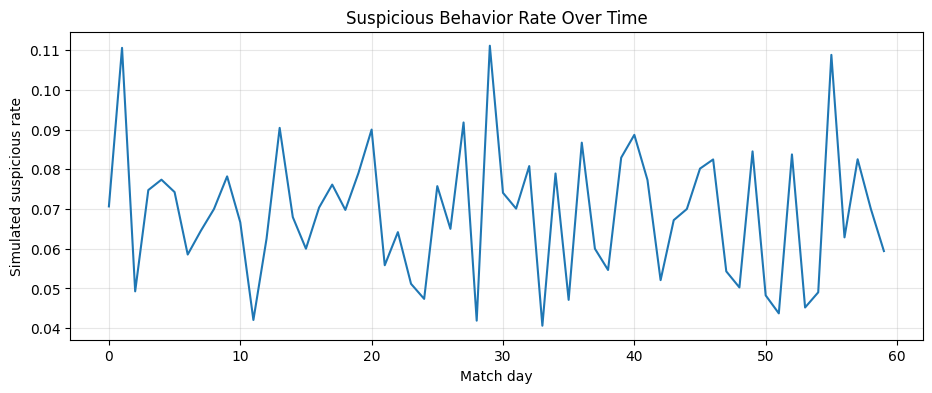

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt

daily_summary = (
    df.groupby("match_day")
      .agg(
          total_observations=("player_id", "size"),
          suspicious_observations=(
              "is_suspicious_simulated", "sum" #using ground truth suspicious simulation
          ),
          avg_actions_per_min=("actions_per_min", "mean")
      )
      .reset_index()
)

daily_summary["suspicious_rate"] = (
    daily_summary["suspicious_observations"]
    / daily_summary["total_observations"]
)

display(daily_summary.head(10))

plt.figure(figsize=(11, 4))
plt.plot(
    daily_summary["match_day"],
    daily_summary["suspicious_rate"]
)

plt.xlabel("Match day")
plt.ylabel("Simulated suspicious rate")
plt.title("Suspicious Behavior Rate Over Time")
plt.grid(alpha=0.3)
plt.show()


Takeaway: Suspicious behavior appears to be concentrated around 0, 30, and 50-match day mark however statistical significance here is not achieved.  While seasonality could be at play, While an element of seasonality could be at play feature distribution needs further investigationthe feature distribution needs further investigationever statistical significance here is not achieved.  While an element of seasonality could be at play, While an element of seasonality could be at play feature distribution needs to be further investigated.

## Feature distribution investigation

We'll investigate four features:
- actions_per_min: gameplay action frequency.
- median_reaction_ms: typical reaction time.
- timing_regularities: simulated consistency of action timing.
- target_accuracy: simulated targeting accuracy.

In [ ]:

import pandas as pd

features = [
    "actions_per_min",
    "median_reaction_ms",
    "timing_regularities",
    "target_accuracy"
]

summary = (
    df.groupby("is_suspicious_simulated")[features]
      .agg(["mean", "median", "std"])
)

display(summary.round(3))


actions_per_min                median_reaction_ms  \
                                   mean median     std               mean   
is_suspicious_simulated                                                     
0                               145.193  145.2  26.551            271.666   
1                               200.311  164.5  85.007            194.861   

                                       timing_regularities                \
                        median     std                mean median    std   
is_suspicious_simulated                                                    
0                        270.7  53.913               0.199  0.177  0.121   
1                        173.7  70.772               0.434  0.490  0.262   

                        target_accuracy                
                                   mean median    std  
is_suspicious_simulated                                
0                                 0.446  0.445  0.105  
1                                 0.492  0.478  0.145

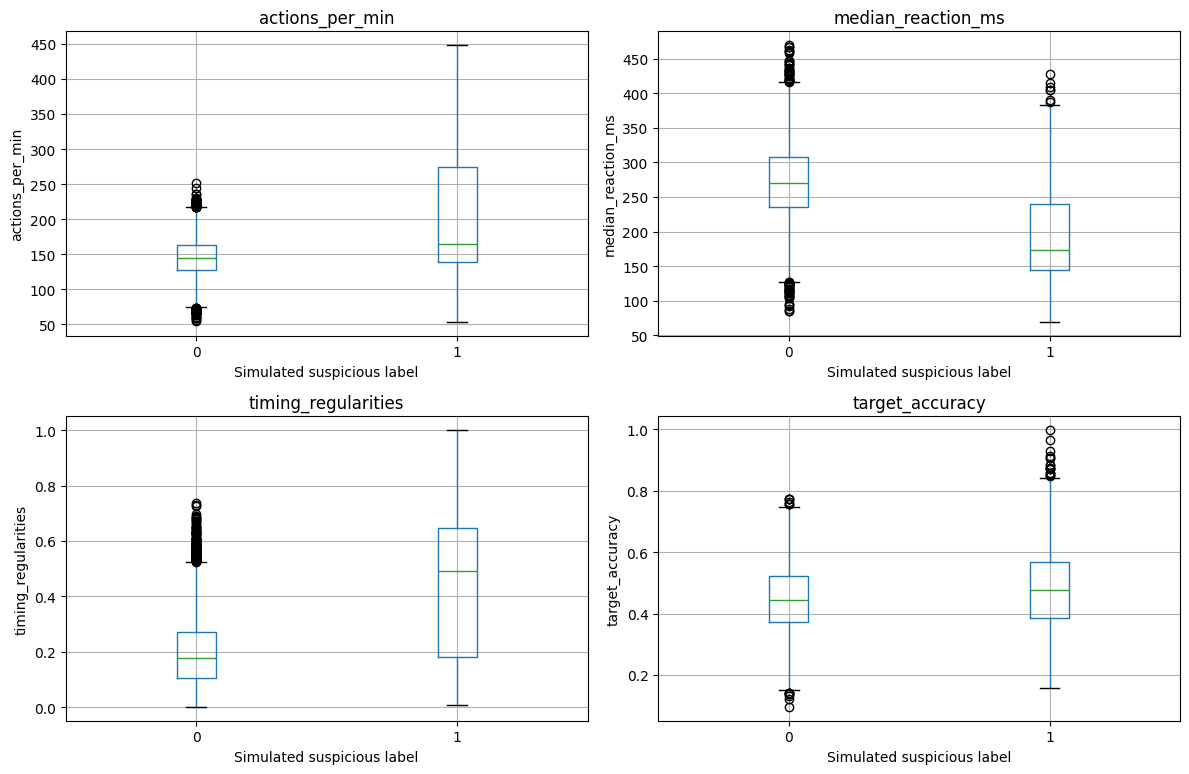

In [ ]:

import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, feature in zip(axes.flatten(), features):
    df.boxplot(
        column=feature,
        by="is_suspicious_simulated",
        ax=ax
    )
    ax.set_title(feature)
    ax.set_xlabel("Simulated suspicious label")
    ax.set_ylabel(feature)

plt.suptitle("")
plt.tight_layout()
plt.show()


It looks like the simulated consistency of action timing is strongly skewed right alongside a lower typical reaction time among the suspicious performing group. However, exceptionally skilled players could have faster reaction reactions time or accuracy that we further need to take into consideration

In [ ]:

# Compare distributions across the two groups
features = [
    "timing_regularities",
    "median_reaction_ms",
    "target_accuracy",
    "skill_proxy"
]

distribution_stats = (
    df.groupby("is_suspicious_simulated")[features]
      .agg(["mean", "median", "std", "skew"])
)

display(distribution_stats.round(3))


timing_regularities                       \
                                       mean median    std   skew   
is_suspicious_simulated                                            
0                                     0.199  0.177  0.121  0.826   
1                                     0.434  0.490  0.262  0.090   

                        median_reaction_ms                        \
                                      mean median     std   skew   
is_suspicious_simulated                                            
0                                  271.666  270.7  53.913  0.026   
1                                  194.861  173.7  70.772  0.841   

                        target_accuracy                      skill_proxy  \
                                   mean median    std   skew        mean   
is_suspicious_simulated                                                    
0                                 0.446  0.445  0.105 -0.004       0.502   
1                                 0.492  0.478  0.145  0.586       0.510   

                                              
                        median    std   skew  
is_suspicious_simulated                       
0                        0.502  0.206 -0.011  
1                        0.510  0.209  0.029

Let's Look at Skill First

In [ ]:

import numpy as np

# Create skill groups
df["skill_group"] = pd.qcut(
    df["skill_proxy"],
    q=5,
    labels=False,
    duplicates="drop"
)

# Median reaction time within each skill group
df["skill_group_median_reaction"] = (
    df.groupby("skill_group")["median_reaction_ms"]
      .transform("median")
)

# Negative values indicate faster-than-group reaction times
df["reaction_time_vs_skill"] = (
    df["median_reaction_ms"]
    - df["skill_group_median_reaction"]
)

display(
    df[
        [
            "skill_proxy",
            "skill_group",
            "median_reaction_ms",
            "skill_group_median_reaction",
            "reaction_time_vs_skill"
        ]
    ].head(10)
)


,skill_proxy,skill_group,median_reaction_ms,skill_group_median_reaction,reaction_time_vs_skill
0,0.616,3,334.8,254.20,80.60
1,0.333,1,290.8,283.45,7.35
2,0.741,4,172.5,235.00,-62.50
3,0.328,1,249.7,283.45,-33.75
4,0.418,1,247.0,283.45,-36.45
5,0.509,2,276.9,267.95,8.95
6,0.376,1,359.8,283.45,76.35
7,0.686,3,260.2,254.20,6.00
8,0.708,4,237.6,235.00,2.60
9,0.780,4,225.8,235.00,-9.20


In [ ]:

# Compare reaction-time features by simulated label
comparison = (
    df.groupby("is_suspicious_simulated")
      .agg(
          count=("player_id", "size"),
          median_raw_reaction=(
              "median_reaction_ms", "median"
          ),
          median_skill_adjusted_reaction=(
              "reaction_time_vs_skill", "median"
          ),
          median_skill=("skill_proxy", "median")
      )
)

display(comparison.round(2))


,count,median_raw_reaction,median_skill_adjusted_reaction,median_skill
is_suspicious_simulated,,,,
0,11171,270.7,2.7,0.50
1,829,173.7,-92.2,0.51


Let's measure feature seperation since we found suspicious activity even after accounting for player skill. Let's see how well they discriminate with reaction_time

In [ ]:

from sklearn.metrics import roc_auc_score

y = df["is_suspicious_simulated"]

# Lower reaction times imply greater suspicion,
# so negate the features for ROC-AUC.
raw_auc = roc_auc_score(
    y,
    -df["median_reaction_ms"]
)

adjusted_auc = roc_auc_score(
    y,
    -df["reaction_time_vs_skill"]
)

print(f"Raw reaction-time AUC: {raw_auc:.3f}")
print(f"Skill-adjusted reaction-time AUC: {adjusted_auc:.3f}")


Raw reaction-time AUC: 0.806
Skill-adjusted reaction-time AUC: 0.806


For a randomly selected suspicious observation and a randomly selected normal observation, the reaction-time score ranks the suspicious observation as more suspicious approximately 80.6% of the time, counting ties appropriately

Make feature engineering leakage-safe - We're going to use a temporal split, since our ultimate goal is to detect suspicious behavior in future gameplay.

In [ ]:

# Sort observations chronologically
df_sorted = df.sort_values("match_day").copy()

# Reserve the latest 20% of days for testing
cutoff_day = df_sorted["match_day"].quantile(0.80)

train_df = df_sorted[
    df_sorted["match_day"] < cutoff_day
].copy()

test_df = df_sorted[
    df_sorted["match_day"] >= cutoff_day
].copy()

print("Cutoff day:", cutoff_day)
print("Training observations:", len(train_df))
print("Testing observations:", len(test_df))

print("\nTraining days:",
      train_df["match_day"].min(),
      "to",
      train_df["match_day"].max())

print("Testing days:",
      test_df["match_day"].min(),
      "to",
      test_df["match_day"].max())

print("\nShared matches:",
      len(
          set(train_df["match_id"])
          & set(test_df["match_id"])
      ))


Cutoff day: 47.0
Training observations: 9382
Testing observations: 2618

Training days: 0 to 46
Testing days: 47 to 59

Shared matches: 1741


a match should not ordinarily occur on multiple days. If match_id identifies a single completed match, finding the same match ID on both sides of a day-based split suggests that our synthetic dataset has inconsistent identifiers or timestamps.
This is different from ordinary player-level leakage. We may have a data-integrity problem. Let's investigate

In [ ]:

# Number of distinct days associated with each match ID
match_day_counts = (
    df.groupby("match_id")["match_day"]
      .nunique()
)

print("Total unique matches:", len(match_day_counts))

print(
    "Match IDs appearing on multiple days:",
    (match_day_counts > 1).sum()
)

print("\nDistribution of distinct days per match:")
display(match_day_counts.value_counts().sort_index())

# Inspect examples of inconsistent match IDs
problem_ids = match_day_counts[
    match_day_counts > 1
].index[:5]

display(
    df[df["match_id"].isin(problem_ids)]
      [["match_id", "match_day", "player_id"]]
      .sort_values(["match_id", "match_day"])
)


Total unique matches: 4563
Match IDs appearing on multiple days: 3439

Distribution of distinct days per match:


,count
match_day,
1,1124
2,1340
3,1061
4,623
5,274
6,91
7,34
8,13
9,3


,match_id,match_day,player_id
6552,200000,0,106552
2944,200000,22,102944
8999,200000,44,108999
5163,200001,3,105163
782,200001,17,100782
6057,200002,0,106057
9054,200002,2,109054
3332,200002,52,103332
2843,200003,5,102843
943,200003,12,100943


I recommend preserving the original data, documenting the limitation, and proceeding with our temporal split for the first detection baseline.
We should exclude match_id from model features and avoid constructing match-level aggregates from it. We've found a genuine data-integrity problem in our synthetic telemetry.

In [ ]:

# Validate the temporal split
assert train_df["match_day"].max() < test_df["match_day"].min()

# Check player overlap
shared_players = (
    set(train_df["player_id"])
    & set(test_df["player_id"])
)

assert len(shared_players) == 0

# Check missing values in model candidates
model_features = [
    "skill_proxy",
    "actions_per_min",
    "median_reaction_ms",
    "timing_regularities",
    "target_accuracy",
    "repeated_action_ratio"
]

assert train_df[model_features].isna().sum().sum() == 0
assert test_df[model_features].isna().sum().sum() == 0

print("Temporal ordering: PASSED")
print("Player overlap: PASSED")
print("Feature completeness: PASSED")

print("\nTraining suspicious rate:",
      round(train_df["is_suspicious_simulated"].mean(), 4))

print("Testing suspicious rate:",
      round(test_df["is_suspicious_simulated"].mean(), 4))


Temporal ordering: PASSED
Player overlap: PASSED
Feature completeness: PASSED

Training suspicious rate: 0.0702
Testing suspicious rate: 0.0649


### STAGE 2: Detection Models

We are starting with logistic regression as a baseline then be more complex

In [ ]:

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score
)

features = [
    "skill_proxy",
    "actions_per_min",
    "median_reaction_ms",
    "timing_regularities",
    "target_accuracy",
    "repeated_action_ratio"
]

X_train = train_df[features]
y_train = train_df["is_suspicious_simulated"]

X_test = test_df[features]
y_test = test_df["is_suspicious_simulated"]

# Scaling is learned from training data only
model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=1000))
])

model.fit(X_train, y_train)

# Predicted suspicious-behavior probabilities
test_probabilities = model.predict_proba(X_test)[:, 1]

print(
    "ROC-AUC:",
    round(roc_auc_score(y_test, test_probabilities), 3)
)

print(
    "PR-AUC (Average Precision):",
    round(average_precision_score(y_test, test_probabilities), 3)
)

print(
    "Test suspicious prevalence:",
    round(y_test.mean(), 3)
)


ROC-AUC: 0.995
PR-AUC (Average Precision): 0.938
Test suspicious prevalence: 0.065


This is near-perfect ROC-AUC should also trigger scientific skepticism.This may be from data that have been generated directly from the same behavioral features we're using to predict it

# Confusion matrix, precision, recall and F1

Confusion Matrix:
[[2425   23]
 [  22  148]]

Classification Report:
              precision    recall  f1-score   support

           0      0.991     0.991     0.991      2448
           1      0.865     0.871     0.868       170

    accuracy                          0.983      2618
   macro avg      0.928     0.931     0.929      2618
weighted avg      0.983     0.983     0.983      2618



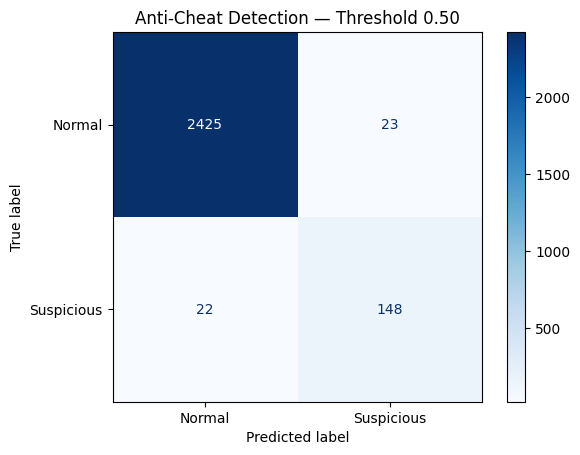

In [ ]:

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Convert probabilities into predictions
threshold = 0.50

y_pred = (
    test_probabilities >= threshold
).astype(int)

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        digits=3
    )
)

# Visualize
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Normal", "Suspicious"]
).plot(cmap="Blues")

plt.title("Anti-Cheat Detection — Threshold 0.50")
plt.show()


While sound - Increasing the classification threshold generally reduces false positives, but also increases false negatives. For an Anti-Cheat system, a conservative threshold can be appropriate when the outcome is severe, such as account suspension. A lower threshold may be reasonable for routing cases to human investigators. Let's do a Threshold sensitivity analysis

In [ ]:

from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd

results = []

for threshold in [0.50, 0.70, 0.85, 0.95]:
    predictions = (
        test_probabilities >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test, predictions, labels=[0, 1]
    ).ravel()

    results.append({
        "threshold": threshold,
        "false_positives": fp,
        "false_negatives": fn,
        "precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "f1": f1_score(
            y_test, predictions, zero_division=0
        ),
        "false_positive_rate": fp / (fp + tn)
    })

threshold_results = pd.DataFrame(results)

display(threshold_results.round(4))


,threshold,false_positives,false_negatives,precision,recall,f1,false_positive_rate
0,0.50,23,22,0.8655,0.8706,0.8680,0.0094
1,0.70,13,36,0.9116,0.7882,0.8454,0.0053
2,0.85,9,48,0.9313,0.7176,0.8106,0.0037
3,0.95,4,68,0.9623,0.6000,0.7391,0.0016


Standardized logistic regression coefficients:


,coefficient
skill_proxy,-3.745
median_reaction_ms,-2.501
repeated_action_ratio,1.316
actions_per_min,1.717
timing_regularities,1.948
target_accuracy,2.701


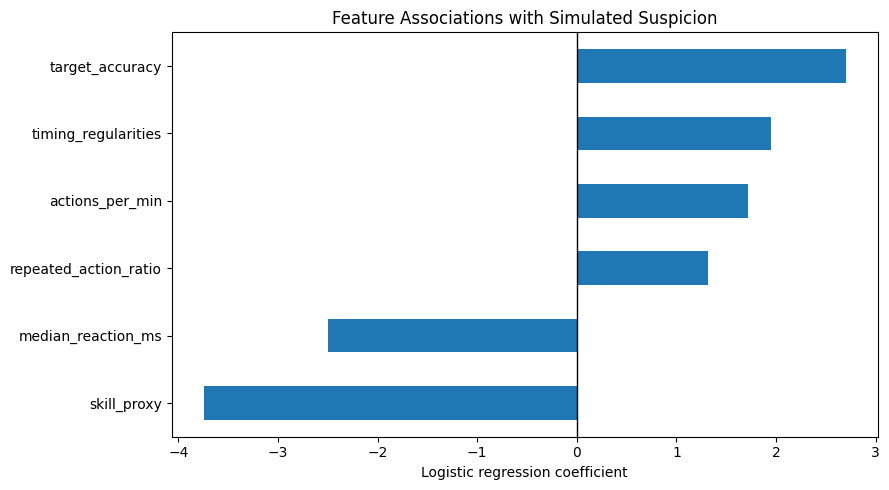

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt

coefficients = pd.Series(
    model.named_steps["classifier"].coef_[0],
    index=features
).sort_values()

print("Standardized logistic regression coefficients:")
display(coefficients.to_frame("coefficient").round(3))

coefficients.plot(
    kind="barh",
    figsize=(9, 5)
)

plt.axvline(0, color="black", linewidth=1)
plt.xlabel("Logistic regression coefficient")
plt.title("Feature Associations with Simulated Suspicion")
plt.tight_layout()
plt.show()


# Unlike logistic regression, Isolation Forest does not learn from the suspicious labels. It identifies observations that are relatively unusual in feature space.

In [ ]:

from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import roc_auc_score, average_precision_score

# Unsupervised anomaly detection
iso_model = Pipeline([
    ("scaler", StandardScaler()),
    ("detector", IsolationForest(
        n_estimators=200,
        contamination=0.07,
        random_state=42
    ))
])

# Fit without suspicious labels
iso_model.fit(X_train)

# Higher score = more anomalous
iso_scores = -iso_model.decision_function(X_test)

print(
    "Isolation Forest ROC-AUC:",
    round(roc_auc_score(y_test, iso_scores), 3)
)

print(
    "Isolation Forest PR-AUC:",
    round(average_precision_score(y_test, iso_scores), 3)
)

print("\nSupervised Logistic Regression:")
print(
    "ROC-AUC:",
    round(roc_auc_score(y_test, test_probabilities), 3)
)
print(
    "PR-AUC:",
    round(average_precision_score(y_test, test_probabilities), 3)
)


Isolation Forest ROC-AUC: 0.975
Isolation Forest PR-AUC: 0.814

Supervised Logistic Regression:
ROC-AUC: 0.995
PR-AUC: 0.938


Do the two models find different suspicious cases?

In [ ]:

import numpy as np
import pandas as pd

# Rank observations by model suspicion scores
review_fraction = 0.05
k = int(np.ceil(len(y_test) * review_fraction))

lr_top = np.argsort(test_probabilities)[-k:]
iso_top = np.argsort(iso_scores)[-k:]

lr_selected = np.zeros(len(y_test), dtype=bool)
iso_selected = np.zeros(len(y_test), dtype=bool)

lr_selected[lr_top] = True
iso_selected[iso_top] = True

labels = np.asarray(y_test)

# Compare model overlap and simulated true positives
print("Review budget:", k, "observations")

print("Flagged by both:",
      np.sum(lr_selected & iso_selected))

print("Flagged only by logistic regression:",
      np.sum(lr_selected & ~iso_selected))

print("Flagged only by Isolation Forest:",
      np.sum(iso_selected & ~lr_selected))

print("\nSuspicious among LR-only:",
      np.sum(labels[lr_selected & ~iso_selected] == 1))

print("Suspicious among IF-only:",
      np.sum(labels[iso_selected & ~lr_selected] == 1))

print("Suspicious among both:",
      np.sum(labels[lr_selected & iso_selected] == 1))


Review budget: 131 observations
Flagged by both: 85
Flagged only by logistic regression: 46
Flagged only by Isolation Forest: 46

Suspicious among LR-only: 40
Suspicious among IF-only: 20
Suspicious among both: 82


In [ ]:

import numpy as np

budget = 131
lr_budget = int(budget * 0.80)
iso_budget = budget - lr_budget

# Rank all observations, highest suspicion first
lr_ranking = np.argsort(-test_probabilities)
iso_ranking = np.argsort(-iso_scores)

# Primary supervised selections
selected = list(lr_ranking[:lr_budget])
selected_set = set(selected)

# Add IF discoveries not already selected
for idx in iso_ranking:
    if idx not in selected_set:
        selected.append(idx)
        selected_set.add(idx)

    if len(selected) == budget:
        break

labels = np.asarray(y_test)

# Compare both strategies at identical capacity
lr_only = lr_ranking[:budget]

lr_precision = labels[lr_only].mean()
hybrid_precision = labels[selected].mean()

print("Review budget:", budget)
print("LR-only suspicious cases:", labels[lr_only].sum())
print("Hybrid suspicious cases:", labels[selected].sum())

print("\nLR-only precision:", round(lr_precision, 3))
print("Hybrid precision:", round(hybrid_precision, 3))


Review budget: 131
LR-only suspicious cases: 122
Hybrid suspicious cases: 119

LR-only precision: 0.931
Hybrid precision: 0.908


For this simulation, I would:
- Use logistic regression as the primary model for prioritizing known suspicious patterns.
- Retain Isolation Forest in a separate exploratory investigation workflow, subject to a small, explicitly allocated review budget.
- Avoid automatic suspensions based on either model's score alone.

### Stage 3 begins: Evaluation and false-positive risk*

Does the model make more mistakes for particular skill groups?

In [ ]:

import numpy as np
import pandas as pd
from sklearn.metrics import (
    precision_score,
    recall_score,
    roc_auc_score
)

evaluation = test_df.copy()

evaluation["predicted_probability"] = test_probabilities
evaluation["predicted_label"] = (
    test_probabilities >= 0.70
).astype(int)

# Skill groups based on the test-set distribution
evaluation["skill_group"] = pd.qcut(
    evaluation["skill_proxy"],
    q=5,
    labels=[
        "Very Low",
        "Low",
        "Medium",
        "High",
        "Very High"
    ],
    duplicates="drop"
)

results = []

for group, subset in evaluation.groupby(
    "skill_group", observed=True
):
    y_true = subset["is_suspicious_simulated"]
    y_pred = subset["predicted_label"]

    false_positives = (
        (y_true == 0) & (y_pred == 1)
    ).sum()

    true_negatives = (
        (y_true == 0) & (y_pred == 0)
    ).sum()

    results.append({
        "skill_group": group,
        "observations": len(subset),
        "suspicious_rate": y_true.mean(),
        "precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "recall": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "false_positive_rate": (
            false_positives /
            (false_positives + true_negatives)
            if false_positives + true_negatives > 0
            else np.nan
        )
    })

subgroup_results = pd.DataFrame(results)

display(subgroup_results.round(4))


,skill_group,observations,suspicious_rate,precision,recall,false_positive_rate
0,Very Low,525,0.0800,0.9688,0.7381,0.0021
1,Low,524,0.0573,0.8333,0.8333,0.0101
2,Medium,524,0.0515,0.8800,0.8148,0.0060
3,High,522,0.0556,0.9091,0.6897,0.0041
4,Very High,523,0.0803,0.9474,0.8571,0.0042


let's calculate 95% confidence intervals for each group's false-positive rate. This will help us distinguish meaningful differences from uncertainty caused by small sample sizes.

In [ ]:

from statsmodels.stats.proportion import proportion_confint
import pandas as pd

interval_results = []

for group, subset in evaluation.groupby(
    "skill_group", observed=True
):
    normal = subset[
        subset["is_suspicious_simulated"] == 0
    ]

    n_normal = len(normal)

    false_positives = (
        normal["predicted_label"] == 1
    ).sum()

    if n_normal > 0:
        lower, upper = proportion_confint(
            count=false_positives,
            nobs=n_normal,
            alpha=0.05,
            method="wilson"
        )
        fpr = false_positives / n_normal
    else:
        lower, upper, fpr = (
            float("nan"),
            float("nan"),
            float("nan")
        )

    interval_results.append({
        "skill_group": group,
        "normal_observations": n_normal,
        "false_positives": false_positives,
        "false_positive_rate": fpr,
        "ci_lower": lower,
        "ci_upper": upper
    })

fpr_intervals = pd.DataFrame(interval_results)

display(fpr_intervals.round(4))


,skill_group,normal_observations,false_positives,false_positive_rate,ci_lower,ci_upper
0,Very Low,483,1,0.0021,0.0004,0.0116
1,Low,494,5,0.0101,0.0043,0.0235
2,Medium,497,3,0.0060,0.0021,0.0176
3,High,493,2,0.0041,0.0011,0.0147
4,Very High,481,2,0.0042,0.0011,0.0150


Network and hardware conditions: Latency, packet loss, frame rate, and input-device differences.



Player tenure and skill: New accounts, experienced players, and unusual skill progression.



Game context: Champion, role, queue type, patch, and match conditions.



Temporal robustness: Performance before and after patches or major gameplay changes.



Enforcement safeguards: Independent evidence, human review, appeals, and monitoring of overturned decisions.

Let's understand trustworthiness

Brier score: 0.0134


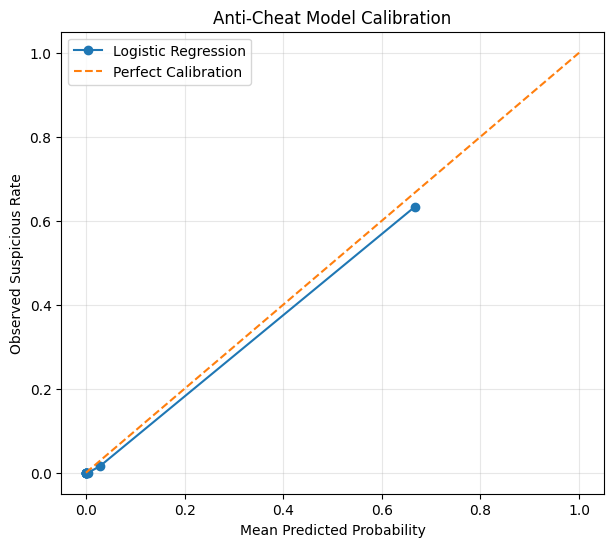

In [ ]:

from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss
import matplotlib.pyplot as plt

fraction_positive, mean_predicted = calibration_curve(
    y_test,
    test_probabilities,
    n_bins=10,
    strategy="quantile"
)

brier = brier_score_loss(
    y_test,
    test_probabilities
)

print("Brier score:", round(brier, 4))

plt.figure(figsize=(7, 6))

plt.plot(
    mean_predicted,
    fraction_positive,
    marker="o",
    label="Logistic Regression"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect Calibration"
)

plt.xlabel("Mean Predicted Probability")
plt.ylabel("Observed Suspicious Rate")
plt.title("Anti-Cheat Model Calibration")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


Our test set has approximately 6.5% suspicious observations. A simple model that predicts the same 6.5% probability for everyone would achieve a Brier score of approximately 0.0607. Remember, a The Brier score measures the average squared difference between predicted probabilities and actual outcomes:

Let's quantitfy calibration cap as Briar score is not enough

In [ ]:

import pandas as pd
import numpy as np

calibration_df = pd.DataFrame({
    "predicted_probability": test_probabilities,
    "actual_label": np.asarray(y_test)
})

calibration_df["bin"] = pd.qcut(
    calibration_df["predicted_probability"],
    q=10,
    duplicates="drop"
)

calibration_summary = (
    calibration_df
    .groupby("bin", observed=True)
    .agg(
        observations=("actual_label", "size"),
        mean_predicted=("predicted_probability", "mean"),
        observed_rate=("actual_label", "mean")
    )
    .reset_index()
)

calibration_summary["gap"] = (
    calibration_summary["observed_rate"]
    - calibration_summary["mean_predicted"]
)

display(calibration_summary.round(4))


,bin,observations,mean_predicted,observed_rate,gap
0,"(-0.00099999701, 4.18e-06]",262,0.0000,0.0000,-0.0000
1,"(4.18e-06, 1.72e-05]",262,0.0000,0.0000,-0.0000
2,"(1.72e-05, 4.6e-05]",262,0.0000,0.0000,-0.0000
3,"(4.6e-05, 0.000123]",261,0.0001,0.0000,-0.0001
4,"(0.000123, 0.000278]",262,0.0002,0.0000,-0.0002
5,"(0.000278, 0.000718]",262,0.0005,0.0000,-0.0005
6,"(0.000718, 0.0021]",261,0.0013,0.0000,-0.0013
7,"(0.0021, 0.0089]",262,0.0042,0.0000,-0.0042
8,"(0.0089, 0.0763]",262,0.0280,0.0153,-0.0127
9,"(0.0763, 1.0]",262,0.6673,0.6336,-0.0337


Evaluation	Result
ROC-AUC	0.995
PR-AUC	0.938
Brier score	0.0134
Highest-decile calibration gap	−0.0337
Highest-decile sample size	262
This is strong performance on the synthetic dataset, and the observed calibration discrepancy is relatively modest.
Before adding complexity, I would investigate calibration specifically among high-risk observations and compare any recalibrated model against the existing baseline on untouched future data.

3. Next exercise: Zoom into the highest-risk observations
Let's split the highest-risk decile into five smaller groups. Each will contain approximately 52 observations, so interpret the resulting rates cautiously.

In [ ]:

# Isolate the highest-risk 10% of predictions
high_risk_cutoff = calibration_df[
    "predicted_probability"
].quantile(0.90)

high_risk = calibration_df[
    calibration_df["predicted_probability"] >= high_risk_cutoff
].copy()

# Split high-risk observations into five bins
high_risk["risk_bin"] = pd.qcut(
    high_risk["predicted_probability"],
    q=5,
    duplicates="drop"
)

high_risk_summary = (
    high_risk
    .groupby("risk_bin", observed=True)
    .agg(
        observations=("actual_label", "size"),
        mean_predicted=("predicted_probability", "mean"),
        observed_rate=("actual_label", "mean")
    )
    .reset_index()
)

high_risk_summary["gap"] = (
    high_risk_summary["observed_rate"]
    - high_risk_summary["mean_predicted"]
)

display(high_risk_summary.round(4))


,risk_bin,observations,mean_predicted,observed_rate,gap
0,"(0.0754, 0.229]",53,0.1257,0.1321,0.0063
1,"(0.229, 0.612]",52,0.4116,0.3654,-0.0462
2,"(0.612, 0.95]",52,0.8255,0.7500,-0.0755
3,"(0.95, 0.996]",52,0.9788,0.9231,-0.0557
4,"(0.996, 1.0]",53,0.9991,1.0000,0.0009


Would retain the logistic regression baseline and document the high-risk calibration discrepancy as a monitoring concern. I would not recalibrate solely on this test set, because doing so would compromise its role as an independent evaluation set. Need to considering sampling uncertainty and checking future data before further recalibrationcheck future data before further recalibration

This interval measures uncertainty around the bin's observed suspicious rate, treating observations as independent. It is a useful diagnostic, not a formal calibration test.

In [ ]:


from statsmodels.stats.proportion import proportion_confint

n = 52
suspicious = 39
mean_predicted = 0.8255

lower, upper = proportion_confint(
    count=suspicious,
    nobs=n,
    alpha=0.05,
    method="wilson"
)

print(f"Observed suspicious rate: {suspicious/n:.3f}")
print(f"95% Wilson interval: [{lower:.3f}, {upper:.3f}]")
print(f"Mean predicted probability: {mean_predicted:.3f}")

print(
    "Predicted mean inside interval:",
    lower <= mean_predicted <= upper
)


Observed suspicious rate: 0.750
95% Wilson interval: [0.618, 0.848]
Mean predicted probability: 0.826
Predicted mean inside interval: True


### Stage 4: Production Deployment

We save the entire preprocessing and classification pipeline to guarantee training-serving consistency. This preserves the fitted feature transformations, model parameters, and expected input schema. During production, it allows us to reproduce predictions, detect compatibility issues, and roll back to a previously validated model version if deployment fails.

In [ ]:

import joblib
import numpy as np

# Save the fitted preprocessing + model pipeline
joblib.dump(model, "anticheat_logistic_pipeline.joblib")

# Reload the saved pipeline
loaded_model = joblib.load(
    "anticheat_logistic_pipeline.joblib"
)

# Verify that reloaded predictions match
original_scores = model.predict_proba(X_test)[:, 1]
reloaded_scores = loaded_model.predict_proba(X_test)[:, 1]

print(
    "Predictions identical:",
    np.allclose(original_scores, reloaded_scores)
)

print(
    "Maximum prediction difference:",
    np.max(np.abs(original_scores - reloaded_scores))
)

print("Model feature count:", loaded_model.n_features_in_)


Predictions identical: True
Maximum prediction difference: 0.0
Model feature count: 6


This verifies prediction reproducibility after serialization. It doesn't yet establish that the model can handle malformed gameplay telemetry, service failures, or production traffic.

Imagine Riot's gameplay telemetry service sends a record to our Anti-Cheat model. What happens if a feature is missing, contains text instead of a number, or has an impossible value?
A production inference component should reject invalid inputs rather than silently produce unreliable predictions.

In [ ]:

import pandas as pd
import numpy as np

FEATURES = [
    "skill_proxy",
    "actions_per_min",
    "median_reaction_ms",
    "timing_regularities",
    "target_accuracy",
    "repeated_action_ratio"
]

def predict_suspicion(record):
    # 1. Check required features
    missing = [f for f in FEATURES if f not in record]

    if missing:
        return {
            "status": "rejected",
            "reason": f"Missing features: {missing}"
        }

    # 2. Validate numeric inputs
    for feature in FEATURES:
        value = record[feature]

        if isinstance(value, (bool, np.bool_)) or not isinstance(
            value, (int, float, np.integer, np.floating)
        ):
            return {
                "status": "rejected",
                "reason": f"{feature} must be numeric"
            }

        if not np.isfinite(value):
            return {
                "status": "rejected",
                "reason": f"{feature} must be finite"
            }

    # 3. Construct model input in training order
    input_df = pd.DataFrame(
        [[record[f] for f in FEATURES]],
        columns=FEATURES
    )

    # 4. Generate probability
    probability = loaded_model.predict_proba(
        input_df
    )[0, 1]

    return {
        "status": "success",
        "suspicion_score": round(float(probability), 4)
    }


# Test A: Valid gameplay record
valid_record = X_test.iloc[0].to_dict()

# Test B: Missing reaction-time feature
invalid_record = valid_record.copy()
invalid_record.pop("median_reaction_ms")

print("Valid input:", predict_suspicion(valid_record))
print("Invalid input:", predict_suspicion(invalid_record))


Valid input: {'status': 'success', 'suspicion_score': 0.0001}
Invalid input: {'status': 'rejected', 'reason': "Missing features: ['median_reaction_ms']"}


Essence, build a small inference function that checks the incoming feature schema before calling the saved model. For data that has missing features, for example, return an explicit status such as insufficient_telemetry. "I would implement fail-safe inference with schema validation and explicit abstention when required features are missing. If the primary model is unavailable, the service may route to a previously validated fallback model, provided its feature requirements are satisfied. I would log input failures, monitor their frequency, and investigate upstream telemetry issues before considering recalibration or retraining. No enforcement decision should be made from an invalid prediction"

In [ ]:

def safe_predict(record, model_available=True):

    # Check telemetry before invoking the model
    missing = [
        feature for feature in FEATURES
        if feature not in record
    ]

    if missing:
        return {
            "status": "insufficient_telemetry",
            "suspicion_score": None,
            "reason": f"Missing features: {missing}"
        }

    # Simulate model service availability
    if not model_available:
        return {
            "status": "model_unavailable",
            "suspicion_score": None,
            "reason": "Primary model unavailable"
        }

    # Use the existing validated inference function
    result = predict_suspicion(record)

    if result["status"] != "success":
        return {
            "status": "insufficient_telemetry",
            "suspicion_score": None,
            "reason": result["reason"]
        }

    return result


print(
    "Normal:",
    safe_predict(valid_record)
)

print(
    "Missing feature:",
    safe_predict(invalid_record)
)

print(
    "Model outage:",
    safe_predict(
        valid_record,
        model_available=False
    )
)


Normal: {'status': 'success', 'suspicion_score': 0.0001}
Missing feature: {'status': 'insufficient_telemetry', 'suspicion_score': None, 'reason': "Missing features: ['median_reaction_ms']"}
Model outage: {'status': 'model_unavailable', 'suspicion_score': None, 'reason': 'Primary model unavailable'}


You made three sound decisions:
1. Continue gameplay. A detection-model outage should not automatically become a game-service outage.
2. Abstain from ML-based enforcement. Missing predictions are not evidence of cheating.
3. Use a validated fallback when possible. A fallback must be independently tested and have the features it requires.

# Let's Look at Latency

In [ ]:

import time
import numpy as np

latencies_ms = []

# Warm up the model
for _ in range(10):
    safe_predict(valid_record)

# Measure individual inference requests
for _ in range(1000):
    start = time.perf_counter()

    result = safe_predict(valid_record)

    elapsed_ms = (
        time.perf_counter() - start
    ) * 1000

    latencies_ms.append(elapsed_ms)

print(
    "Mean latency (ms):",
    round(np.mean(latencies_ms), 3)
)

print(
    "P50 latency (ms):",
    round(np.percentile(latencies_ms, 50), 3)
)

print(
    "P95 latency (ms):",
    round(np.percentile(latencies_ms, 95), 3)
)

print(
    "P99 latency (ms):",
    round(np.percentile(latencies_ms, 99), 3)
)


Mean latency (ms): 2.608
P50 latency (ms): 1.983
P95 latency (ms): 6.1
P99 latency (ms): 10.059


In [ ]:

import time
import numpy as np
import pandas as pd

construction_times = []
inference_times = []

for _ in range(1000):
    start = time.perf_counter()

    input_df = pd.DataFrame(
        [[valid_record[f] for f in FEATURES]],
        columns=FEATURES
    )

    after_construction = time.perf_counter()

    loaded_model.predict_proba(input_df)

    after_inference = time.perf_counter()

    construction_times.append(
        (after_construction - start) * 1000
    )

    inference_times.append(
        (after_inference - after_construction) * 1000
    )

for name, values in [
    ("DataFrame construction", construction_times),
    ("Model pipeline inference", inference_times)
]:
    print(f"\n{name}")
    print("Mean:", round(np.mean(values), 3), "ms")
    print("P95:", round(np.percentile(values, 95), 3), "ms")
    print("P99:", round(np.percentile(values, 99), 3), "ms")



DataFrame construction
Mean: 0.361 ms
P95: 0.465 ms
P99: 2.446 ms

Model pipeline inference
Mean: 2.019 ms
P95: 4.055 ms
P99: 6.538 ms


Our initial profiling indicates that model-pipeline execution dominates local inference latency, with a P99 of approximately 6.5 milliseconds. Given the relatively simple model architecture, I would first establish production latency and throughput requirements, then profile preprocessing, model execution, and serving overhead independently. I would collaborate with ML platform and infrastructure engineers to determine whether batching, runtime optimization, or asynchronous inference is necessary before deployment

In [ ]:

import pandas as pd
import numpy as np

# Simulate 1,000 production requests
rng = np.random.default_rng(42)

records = X_test.sample(
    n=1000,
    random_state=42
).to_dict("records")

results = []

for record in records:
    event = rng.choice(
        ["normal", "missing_feature", "outage"],
        p=[0.94, 0.04, 0.02]
    )

    request = record.copy()

    if event == "missing_feature":
        request.pop("median_reaction_ms")

    result = safe_predict(
        request,
        model_available=(event != "outage")
    )

    results.append(result)

monitoring_df = pd.DataFrame(results)

print("Request status counts:")
print(monitoring_df["status"].value_counts())

print("\nRequest status percentages:")
print(
    monitoring_df["status"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("\nSuccessful prediction rate:")
print(
    round(
        monitoring_df["status"].eq("success").mean() * 100,
        2
    ),
    "%"
)


Request status counts:
status
success                   944
insufficient_telemetry     33
model_unavailable          23
Name: count, dtype: int64

Request status percentages:
status
success                   94.4
insufficient_telemetry     3.3
model_unavailable          2.3
Name: proportion, dtype: float64

Successful prediction rate:
94.4 %


Identify the failure category.
Break down the unsuccessful 6% by insufficient_telemetry, model_unavailable, timeout, and unexpected exceptions. Compare against the pre-patch baseline.



Protect players and stabilize the service.
Continue gameplay, abstain from ML-based enforcement for invalid predictions, and alert the on-call ML platform team. Use a validated fallback only when compatible.



Investigate the patch deployment.
Check whether feature names, schemas, telemetry availability, service versions, or dependencies changed. Compare affected regions and game modes.



Recover and verify.
Roll back a faulty deployment or fix the ingestion/service issue. Verify that success rates, error categories, and latency return to acceptable levels.



Evaluate model quality separately.
Only investigate retraining or recalibration if the patch also changed gameplay behavior, feature distributions, or the relationship between predictions and outcomes.

Cheating Preference with Reviewed Players vs

In [ ]:

import numpy as np
import pandas as pd

rng = np.random.default_rng(42)

n_players = 100_000

players = pd.DataFrame({
    "player_id": np.arange(n_players),
    "skill_proxy": rng.uniform(0, 1, n_players),
    "tenure_days": rng.integers(1, 1500, n_players),
    "region": rng.choice(
        ["NA", "EU", "KR", "BR"],
        size=n_players
    )
})

# Hidden synthetic ground truth
players["true_cheating"] = rng.binomial(
    1, 0.025, n_players
)

# Existing detector is more likely to flag
# cheating players, but misses some.
flag_probability = np.where(
    players["true_cheating"] == 1,
    0.70,
    0.035
)

players["old_model_flag"] = (
    rng.random(n_players) < flag_probability
).astype(int)

# Only flagged players receive investigation labels
players["reviewed"] = players["old_model_flag"]

players["observed_label"] = np.where(
    players["reviewed"] == 1,
    players["true_cheating"],
    np.nan
)

print("Total players:", len(players))
print("True cheating prevalence:",
      round(players["true_cheating"].mean(), 4))
print("Flagged players:",
      players["old_model_flag"].sum())
print("Reviewed players:",
      players["reviewed"].sum())
print("Unlabeled players:",
      players["observed_label"].isna().sum())

print("\nObserved label counts:")
print(players["observed_label"].value_counts(dropna=False))


Total players: 100000
True cheating prevalence: 0.0243
Flagged players: 5150
Reviewed players: 5150
Unlabeled players: 94850

Observed label counts:
observed_label
NaN    94850
0.0     3446
1.0     1704
Name: count, dtype: int64
